# Cross-season apple-tree matching: preparation and targeted review

**Current scope: 1. configuration and data auditing; 2. filename labels, human records, and row splits; 3. ORB/RANSAC features and targeted review.**
Linear Regression remains the future baseline and RBF-SVR the main regression method.
This notebook does not currently train regression models. HOG is not used.

R denotes the orchard row, N a candidate matched tree number, and U an unmatched observation.
GT is a 2D branch mask. Retain filename labels by default, excluding explicit human rejections.
Unverified pairs are never recorded as human-confirmed. D has unknown physical units;
current screening uses RGB and does not produce metric 3D coordinates.

Dataset background: [Chen et al. (2020)](https://arxiv.org/pdf/2010.06879).
The paper's 521 annotated images differ from the local version, so this project defines its own split.
ORB uses a center-square crop (480×480 from a 640×480 image), resized to 256×256.


## 1. Configuration and data auditing

Start Jupyter from the project environment and select **Restart Kernel and Run All Cells**.
The default dataset root is `data/TreeID/TreeID`; override it in the ignored
`config/local.json` or the `MMA3001_DATA_ROOT` environment variable.
Original images are read-only. Preparation outputs go to `outputs/data_preparation/`.

Choose the MMA3001 kernel. Stage 3 requires OpenCV; `nbformat` and `nbclient` support automated execution.


In [1]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/experiment.json").is_file() and (p / "src/main.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the project root directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.main import get_runtime_versions, load_config, run_data_preparation
from src.utils import index_dataset, read_rgb, read_depth

config = load_config(ROOT)
SYNTHETIC = os.environ.get("MMA3001_SYNTHETIC") == "1"
if SYNTHETIC:
    config.update(output_dir="outputs/synthetic_data_preparation",
                  review_file="outputs/synthetic_data_preparation/pair_review.csv")
    display(Markdown("**Synthetic CI demonstration: these counts are not real orchard experiment results.**"))
DATA_ROOT = Path(config["data_root"])
if not DATA_ROOT.is_absolute():
    DATA_ROOT = ROOT / DATA_ROOT
print("Seed:", config["seed"], "| model training: disabled")
print("Python:", sys.executable)
versions = get_runtime_versions()
display(pd.DataFrame({"package": list(versions),
                      "version": [version or "metadata unavailable" for version in versions.values()]}))


Seed: 42 | model training: disabled
Python: D:\anacoda3\envs\MMA3001\python.exe


,package,version
0,numpy,2.5.4
1,pandas,3.0.6
2,Pillow,13.0.0
3,matplotlib,3.11.2


### 1.1 Filename parsing, image quality, and content hashes

Parse identity from the filename **prefix**. For example,
`R04N01_Winter_D-R04N05_RGB_12-17-20.png` has current identity `R04N01`;
the older ID in its suffix does not override the prefix.
Check RGB readability, dimensions, and SHA-256. D must be uint8 grayscale or
three equal grayscale channels, with dimensions matching RGB.
Record missing or unsupported D while retaining valid RGB observations.


In [2]:
index = index_dataset(DATA_ROOT)
overview = index.groupby(["kind", "season"]).agg(
    observations=("tree_id", "size"), valid_rgb=("valid_rgb", "sum"),
    rgb_width=("width", "min"), rgb_height=("height", "min"),
    gt_images=("gt_path", lambda values: values.ne("").sum()))
display(overview)
display(index[["tree_id", "season", "width", "height", "rgb_status", "depth_status",
               "depth_zero_fraction", "gt_status", "gt_width", "gt_height"]].head(8))
print("Observations with corrected / non-time-only suffix:", int(index["special_suffix"].sum()))
print("RGB status:", index["rgb_status"].value_counts().to_dict())
print("D status:", index["depth_status"].value_counts().to_dict())


observations  valid_rgb  rgb_width  rgb_height  gt_images
kind season                                                           
N    Summer           562        562        640         480        562
     Winter           562        562        640         480          0
U    Summer           544        544        640         480          0
     Winter           544        544        640         480          0

,tree_id,season,width,height,rgb_status,depth_status,depth_zero_fraction,gt_status,gt_width,gt_height
0,R01U01,Summer,640,480,ok,ok,0.180114,not_provided,0,0
1,R01U01,Winter,640,480,ok,ok,0.540365,not_provided,0,0
2,R01U02,Summer,640,480,ok,ok,0.029844,not_provided,0,0
3,R01U02,Winter,640,480,ok,ok,0.504479,not_provided,0,0
4,R01U03,Summer,640,480,ok,ok,0.123298,not_provided,0,0
5,R01U03,Winter,640,480,ok,ok,0.548975,not_provided,0,0
6,R01U04,Summer,640,480,ok,ok,0.063363,not_provided,0,0
7,R01U04,Winter,640,480,ok,ok,0.448184,not_provided,0,0


Observations with corrected / non-time-only suffix: 52
RGB status: {'ok': 2212}
D status: {'ok': 2212}


### 1.2 Inspect sample observations

RGB and D share the same pixel field of view. Display GT separately: its different
size prevents directly overlaying it on the original image without a defined transform.
The D zero-intensity fraction is descriptive; intensities are not converted to distance.


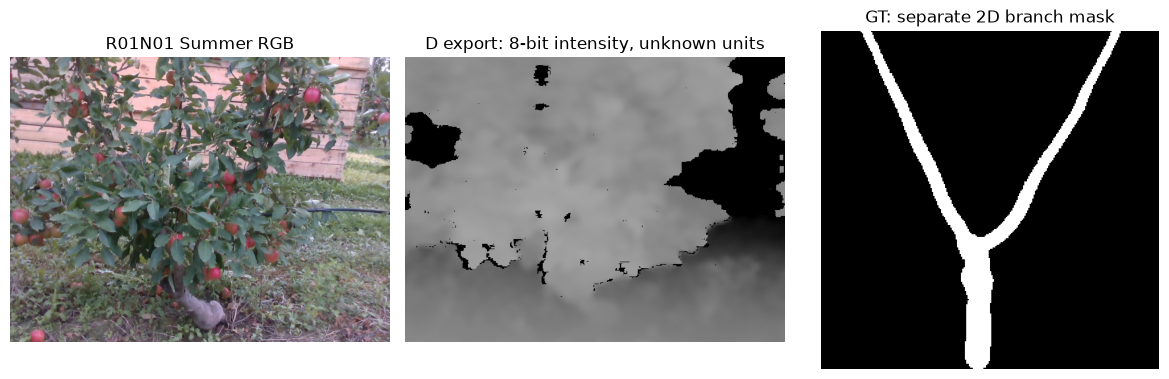

In [3]:
sample = index[index["kind"].eq("N") & index["season"].eq("Summer") & index["valid_rgb"]].iloc[0]
rgb = read_rgb(sample["rgb_path"])
depth, depth_status = read_depth(sample["depth_path"], rgb.shape[:2])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(rgb)
axes[0].set_title(f"{sample['tree_id']} Summer RGB")
if depth is not None:
    axes[1].imshow(depth, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("D export: 8-bit intensity, unknown units")
if sample["gt_path"]:
    from PIL import Image as PILImage
    with PILImage.open(sample["gt_path"]) as gt_image:
        axes[2].imshow(np.asarray(gt_image), cmap="gray", vmin=0, vmax=255)
axes[2].set_title("GT: separate 2D branch mask")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
plt.show()


## 2. Filename labels, human records, and row splits

Build Summer/Winter candidate pairs only for equal N `(R,N)` identities. U observations do not receive pair labels.
Assign row membership before human exclusions: 20 rows become 12/4/4 train/validation/test rows, seed=42.
Rows, identities, RGB paths, and identical RGB content must not cross splits.

Preserve existing human records. Two pairs per row and all R04 pairs formed the initial spot checks.
Current work uses optional targeted batches rather than requiring full manual verification.
`human_verified` and `label_basis` distinguish human confirmation from filename labels.
The eight observations unresolved because of occlusion retain pending status and original notes;
under the current policy their original filename labels are retained.


In [4]:
result = run_data_preparation(ROOT, config=config, render=True, index=index)
cases = result["cases"]
summary = result["summary"]
display(cases.groupby("split").agg(rows=("row", "nunique"), tree_pairs=("tree_id", "size")))
row_assignment = cases.groupby(["row", "split"]).size().rename("tree_pairs").reset_index()
display(row_assignment)


Part 1: reading image headers, RGB content hashes and D/GT quality...


Part 2: 562 proposed N pairs; U observations stay unlabelled.


{
  "stage": "1_config_and_data_audit__2_label_review_and_row_split",
  "models_trained": false,
  "observations": 2212,
  "valid_rgb_observations": 2212,
  "proposed_n_pairs": 562,
  "eligible_n_pairs": 549,
  "unmatched_u_observations": 1088,
  "review_required": 59,
  "review_pending": 8,
  "review_confirmed": 38,
  "review_rejected": 13,
  "label_status": "filename_labels_with_partial_human_verification",
  "eligible_human_verified": 38,
  "eligible_filename_unverified": 511,
  "review_policy": "targeted_review; no automatic approvals or score-based exclusions",
  "split_rows": {
    "test": 4,
    "train": 12,
    "validation": 4
  },
  "split_trees": {
    "test": 132,
    "train": 305,
    "validation": 112
  },
  "leakage_checks_passed": true,
  "seed": 42,
  "depth_metric_scale": "unknown",
  "source_paper": "https://arxiv.org/pdf/2010.06879",
  "split_manifest_sha256": "1ef46890640224d76e5fa16a047741a6bea026f933c0f2212b34f09b8f229be5"
}


8 early spot-check pairs remain unresolved; targeted review retains their filename labels.


,rows,tree_pairs
split,,
test,4,132
train,12,305
validation,4,112


,row,split,tree_pairs
0,R01,train,44
1,R02,test,43
2,R03,validation,34
3,R04,train,15
4,R05,validation,34
5,R06,train,31
6,R07,train,32
7,R08,train,21
8,R09,test,34
9,R10,train,28


### 2.1 Human review records

`config/pair_review.csv` stores human decisions and notes. Reading an existing ledger does not overwrite its bytes.

- `confirmed`: a human confirmed that the images show the same tree.
- `rejected`: a human rejected the identity; rerunning excludes it from labelled queries and galleries.
- `pending`: not independently verified, or explicitly unresolved; retain the filename label and its provenance.

`required_review` identifies the initial spot-check set, not a confirmation.
The sheets below cover that original set. The full 562-pair atlas is optional.


,tree_id,row,required_review,human_status,human_notes
3,R01N04,R01,True,confirmed,主干弯曲和低处分叉一致，确认同树
34,R01N35,R01,True,confirmed,主干弯曲和低处分叉一致，确认同树
62,R02N19,R02,True,confirmed,主干弯曲和低处分叉一致，确认同树
86,R02N43,R02,True,confirmed,主干弯曲和低处分叉一致，确认同树
89,R03N03,R03,True,confirmed,主干弯曲和低处分叉一致，确认同树
110,R03N24,R03,True,confirmed,主干弯曲和低处分叉一致，确认同树
121,R04N01,R04,True,confirmed,主干弯曲和低处分叉一致，确认同树
122,R04N02,R04,True,confirmed,主干弯曲和低处分叉一致，确认同树
123,R04N03,R04,True,confirmed,主干弯曲和低处分叉一致，确认同树
124,R04N04,R04,True,rejected,主干结节不同


**Initial spot-check set: 59 pairs; unresolved: 8. Current policy: targeted review.**

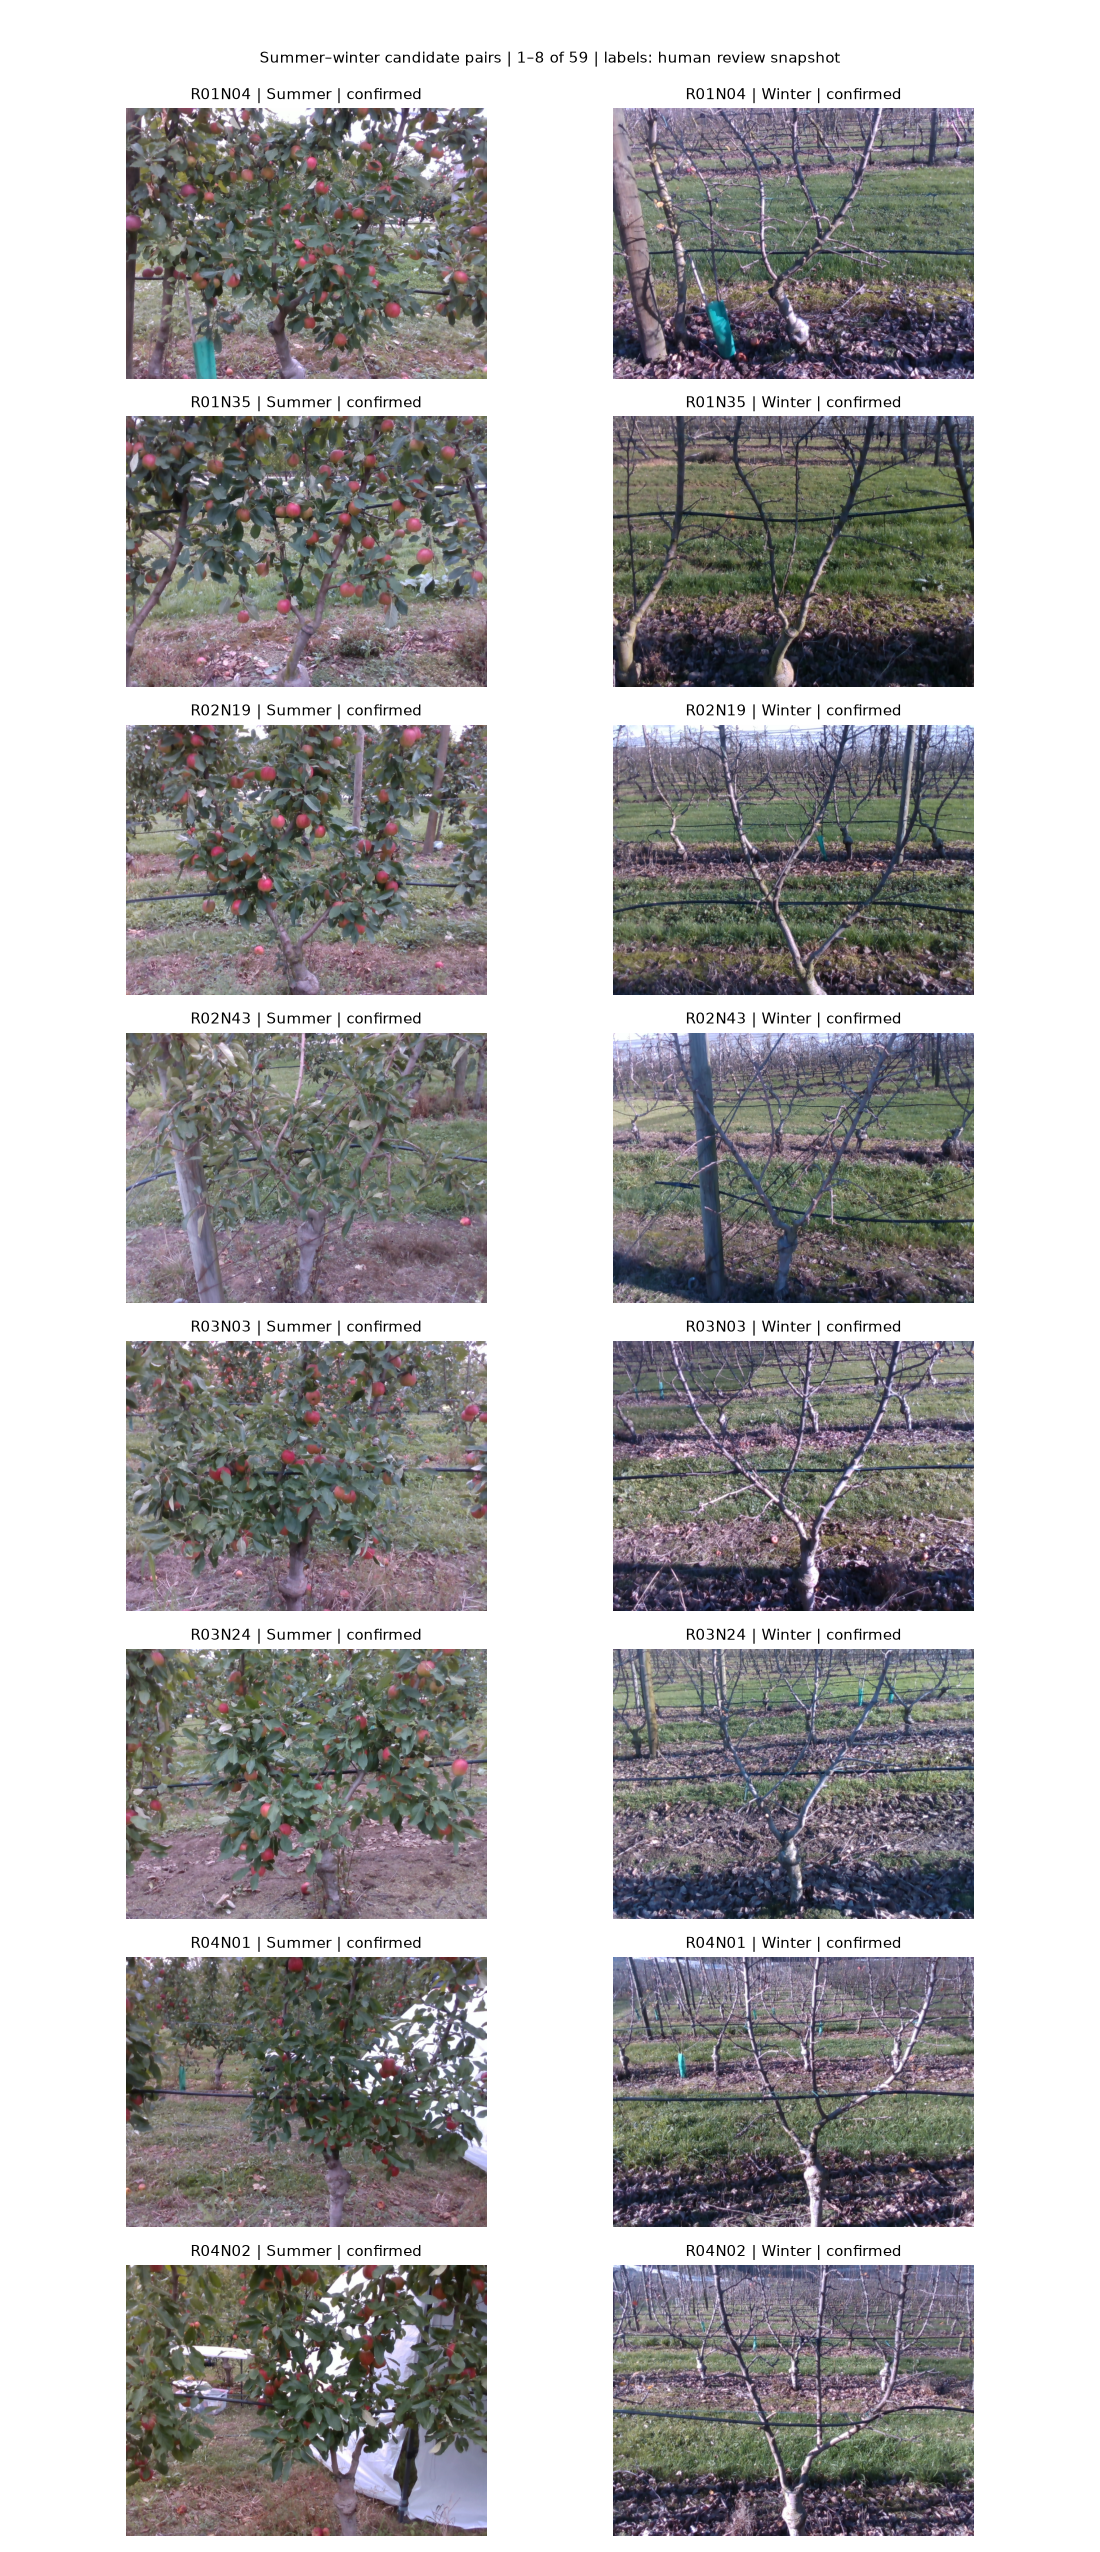

outputs/data_preparation/review_sheets/review_01.png
outputs/data_preparation/review_sheets/review_02.png
outputs/data_preparation/review_sheets/review_03.png
outputs/data_preparation/review_sheets/review_04.png
outputs/data_preparation/review_sheets/review_05.png
outputs/data_preparation/review_sheets/review_06.png
outputs/data_preparation/review_sheets/review_07.png
outputs/data_preparation/review_sheets/review_08.png


In [5]:
review = result["review"]
display(review.loc[review["required_review"],
                   ["tree_id", "row", "required_review", "human_status", "human_notes"]].head(12))
display(Markdown(f"**Initial spot-check set: {summary['review_required']} pairs; unresolved: {summary['review_pending']}. Current policy: targeted review.**"))
if result["contact_sheets"]:
    display(DisplayImage(filename=str(result["contact_sheets"][0]), width=820))
for path in result["contact_sheets"]:
    print(path.relative_to(ROOT).as_posix())


### 2.2 Leakage checks, exclusions, and the R/N index diagram

Export identical RGB content separately. Duplicates crossing N train/validation/test splits raise an error.
Content overlap involving U is audited without treating U as an independent matched identity.
The plot below uses row and tree indices, not GPS positions or coordinates in metres.


,split_a,split_b,field,overlap_count,passed
0,train,validation,row,0,True
1,train,validation,tree_id,0,True
2,train,validation,rgb_path,0,True
3,train,validation,rgb_sha256,0,True
4,train,test,row,0,True
5,train,test,tree_id,0,True
6,train,test,rgb_path,0,True
7,train,test,rgb_sha256,0,True
8,validation,test,row,0,True
9,validation,test,tree_id,0,True


,subset,tree_id,reason
0,Dataset (With Summer GT),R04N04,human_rejected
1,Dataset (With Summer GT),R04N05,human_rejected
2,Dataset (With Summer GT),R04N08,human_rejected
3,Dataset (With Summer GT),R04N13,human_rejected
4,Dataset (With Summer GT),R04N14,human_rejected
5,Dataset (With Summer GT),R04N16,human_rejected
6,Dataset (With Summer GT),R06N25,human_rejected
7,Dataset (With Summer GT),R08N08,human_rejected
8,Dataset (With Summer GT),R10N24,human_rejected
9,Dataset (With Summer GT),R12N19,human_rejected


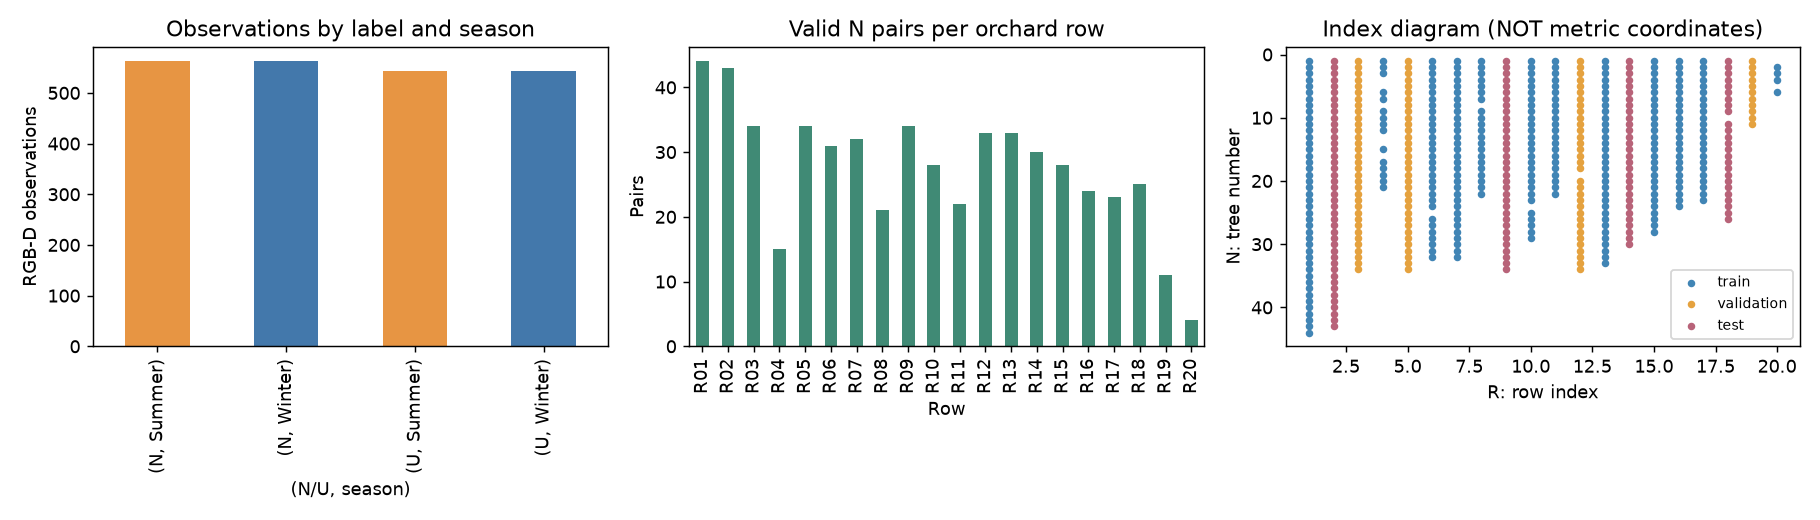

In [6]:
display(result["leakage"])
display(result["exclusions"])
assert result["leakage"]["passed"].all()
assert not summary["models_trained"]
display(DisplayImage(filename=str(result["figures"][0]), width=1100))


### 2.3 Reproducible outputs and current scope

`outputs/data_preparation/` contains:

- `observation_index.csv`: observations, hashes, and D/GT status;
- `split_manifest.csv`: fixed identity-level split and label provenance;
- `train/validation/test_queries.csv` and matching `*_gallery.csv` retrieval inputs;
- `quality_issues.csv`, `special_filenames.csv`, `duplicate_rgb_content.csv`, and `excluded_n_pairs.csv`;
- `leakage_checks.csv`, `summary.json`, `review_sheets/`, and `figures/`.

Image paths are project-relative when possible. Filename labels define fixed row membership;
record human verification separately and exclude explicit rejections.
Future regression models share these splits. Test data is not used to select features or screening parameters.

This notebook continues with stage 3 screening and independent sampling. Systematic numerical
verification, Linear Regression, RBF-SVR, and final model comparisons remain later stages.


In [7]:
print("Split manifest SHA-256:", summary["split_manifest_sha256"])
print("Label status:", summary["label_status"])
print("Leakage checks passed:", summary["leakage_checks_passed"])
print("Models trained:", summary["models_trained"])
print("Generated outputs:", result["output_dir"].relative_to(ROOT).as_posix())


Split manifest SHA-256: 1ef46890640224d76e5fa16a047741a6bea026f933c0f2212b34f09b8f229be5
Label status: filename_labels_with_partial_human_verification
Leakage checks passed: True
Models trained: False
Generated outputs: outputs/data_preparation


### 2.4 Freeze the independent test sample before scoring

Before extracting ORB features or viewing automated scores, uniformly sample 40 eligible
queries from the original test rows, seed=42. Create the fixed query list and complete winter
test gallery once for both future models. Reruns do not resample or replace difficult queries.

Independent entries start as pending. They do not inherit previous confirmations or show alternative candidates.
Record decisions in `config/evaluation/independent_review.csv`. Final evaluation must report
sampled count, confirmed/rejected/unresolved cases, and uncertainty. Unverified labels are not independent truth.


In [8]:
from src.main import portable_frame
from src.screening import load_screening_config, freeze_evaluation, run_targeted_review

screen_settings = load_screening_config(ROOT)
if SYNTHETIC:
    # CI uses temporary protocol files and tiny samples, never the real frozen test list.
    scratch = Path(os.environ["MMA3001_DATA_ROOT"]).parent
    screen_settings.update(evaluation_queries=2, workers=2, max_review_cases=10,
                           evaluation_dir=str(scratch / "evaluation_protocol"),
                           output_dir=str(scratch / "targeted_review"),
                           cache_dir=".cache/synthetic_orb_screening")
independent_test = freeze_evaluation(portable_frame(cases, ROOT), ROOT, screen_settings)
print("Frozen test queries:", len(independent_test["queries"]))
print("Complete test gallery:", len(independent_test["gallery"]))
print("Independent review states:", independent_test["review"]["independent_status"].value_counts().to_dict())
display(independent_test["queries"][["tree_id", "row"]].head(8))


Frozen test queries: 40
Complete test gallery: 132
Independent review states: {'pending': 40}


,tree_id,row
0,R02N09,R02
1,R02N10,R02
2,R02N12,R02
3,R02N15,R02
4,R02N21,R02
5,R02N29,R02
6,R02N37,R02
7,R02N43,R02


## 3. ORB/RANSAC features and targeted review

Extract up to 500 ORB keypoints and use Hamming distance for binary descriptors.
Apply a two-neighbour ratio test of 0.75 and retain at most one correspondence per target keypoint.
Fit a full 2D affine transform with RANSAC: 3 px threshold in 256×256 coordinates,
maxIters=2000, confidence=0.99. Retain pairs with missing descriptors, too few points,
or degenerate geometry, with explicit missing/failed-estimation flags.

The evidence heuristic is `inlier_count × inlier_ratio`, set to zero below six inliers.
It is not a probability or identity truth. Seasonal change can lower the original pair's score;
supports and repeated backgrounds can increase an incorrect candidate's score.
Preserve geometric rank tie ranges rather than imply reliable ordering without evidence.

Screen only training/validation queries against their split's **entire winter gallery**.
Row numbers do not restrict candidates. Test queries are not scored. Code and caches can support
future regression features; identity, row, and filename are indexing metadata only.

References: [OpenCV feature matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html),
[affine estimation](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html), and
[VPR-Bench](https://link.springer.com/article/10.1007/s11263-021-01469-5), which discusses
appearance/viewpoint changes and perceptual aliasing.


In [9]:
screening = run_targeted_review(ROOT, preparation=result, settings=screen_settings, render=True)
print("Pair comparisons:", screening["summary"]["timings"]["pair_count"])
print("Models trained:", screening["summary"]["models_trained"])
print("Automatic human-label updates:", screening["summary"]["automatic_labels_written"])
print("Test pair scores computed:", screening["summary"]["test_pair_scores_computed"])
assert screening["summary"]["ledger_unchanged"]
assert not screening["pair_features"]["split"].eq("test").any()


Frozen independent test queries: 40; full gallery: 132


Image features: 100/834


Image features: 200/834


Image features: 300/834


Image features: 400/834


...

Full-gallery query comparisons: 400/417 (400 reused)


Full-gallery query comparisons: 417/417 (417 reused)

Rendered optional review batch 1: 1 cases


{
  "models_trained": false,
  "automatic_labels_written": false,
  "eligible_pairs": 549,
  "excluded_human_rejected": 13,
  "human_verified_pairs": 38,
  "filename_unverified_pairs": 511,
  "screened_splits": [
    "train",
    "validation"
  ],
  "screened_queries": 417,
  "queued_for_optional_review": 385,
  "rendered_review_cases": 1,
  "queries_with_geometric_evidence": 0,
  "queries_without_geometric_evidence": 417,
  "screening_quality": "insufficient_geometry_for_reliable_prioritisation",
  "batch_size": 20,
  "independent_test_queries": 40,
  "full_test_gallery": 132,
  "independent_review_status": {
    "pending": 40
  },
  "test_protocol_frozen_before_features": true,
  "test_pair_scores_computed": 0,
  "ledger_sha256": "28abe05271c3188c5f15abf51170f5d8727ee195c091f34a03bc25679714bc3c",
  "ledger_unchanged": true,
  "opencv_version": "5.0.0"
}


Pair comparisons: 105569
Models trained: False
Automatic human-label updates: False
Test pair scores computed: 0


### 3.1 Optional batches without forcing low-evidence rankings

Each batch contains at most 20 cases, with a maximum of 60 supported-priority cases per run.
Include filename-suffix anomalies or distinguishing geometric evidence. Preserve full geometric
ties when every score is zero; descriptor distance does not break those geometric ties.
The three alternative images are weak descriptor examples when geometry is insufficient,
not independently supported replacement identities. Do not pad batches when few cases qualify.

A human may retain the original label, note uncertainty, or reject a pair based on independent
image evidence. The program does not automatically re-pair images or delete cases because
a final SVR prediction is wrong.


Screening quality: insufficient_geometry_for_reliable_prioritisation
Queries without geometric evidence: 417


,review_priority,query_id,split,issue_tags,original_inliers,original_inlier_ratio,original_rank_min,original_rank_max,alternative_1,alternative_margin,evidence_status
0,1,R04N09,train,special_filename_suffix;weak_original_geometry...,0.0,0.0,1,305,R01N02,0.0,insufficient_geometry


Review atlas: D:\2026-S2\MMA3001\MMA3001_project\outputs\targeted_review\index.html
Blind test atlas: D:\2026-S2\MMA3001\MMA3001_project\outputs\targeted_review\independent_test\index.html


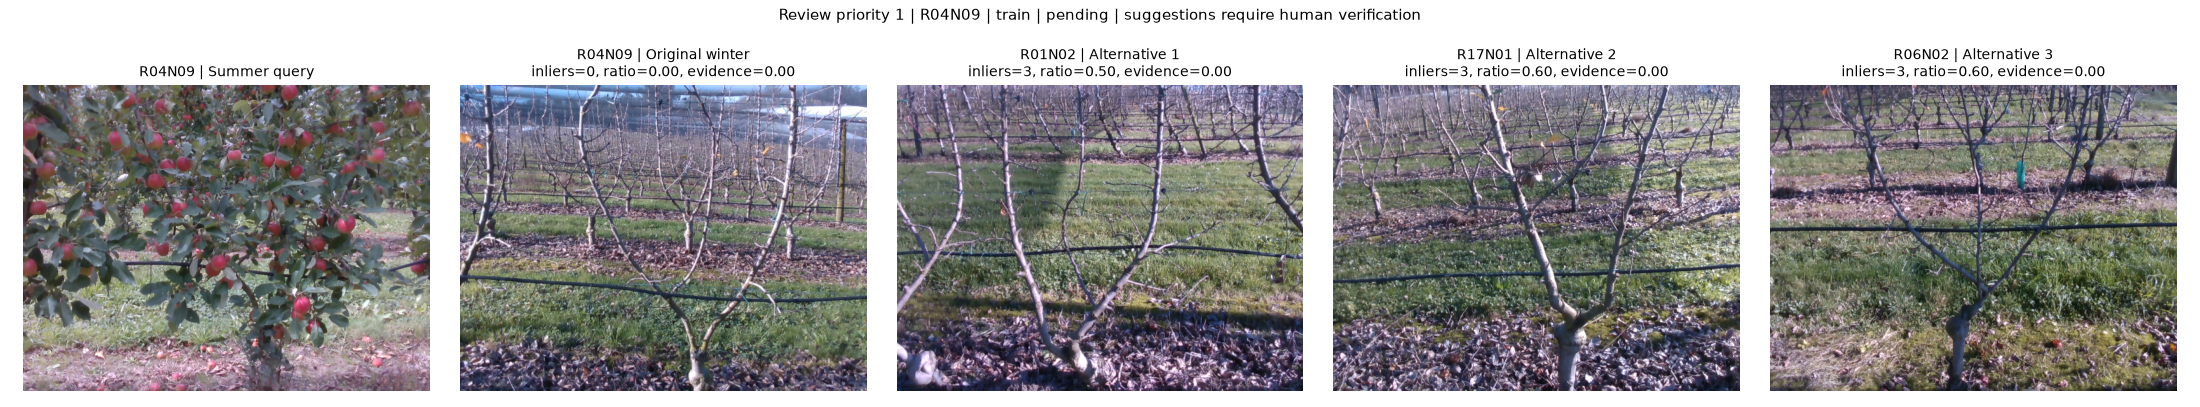

In [10]:
columns = ["review_priority", "query_id", "split", "issue_tags", "original_inliers",
           "original_inlier_ratio", "original_rank_min", "original_rank_max", "alternative_1", "alternative_margin", "evidence_status"]
print("Screening quality:", screening["summary"]["screening_quality"])
print("Queries without geometric evidence:", screening["summary"]["queries_without_geometric_evidence"])
display(screening["batches"][columns].head(20))
print("Review atlas:", screening["links"]["index"])
print("Blind test atlas:", screening["links"]["independent_test"])
if not screening["batches"].empty:
    first_case = screening["batches"].iloc[0]
    filename = f"case_{first_case['review_priority']:03d}_{first_case['query_id']}.png"
    display(DisplayImage(filename=str(screening["output_dir"] / "review_batches/images" / filename), width=1350))


### 3.2 Training-only ORB parameter diagnostic

Check resolution and ratio effects when the defaults provide insufficient evidence.
Use up to 20 human-confirmed training pairs and 10 different-filename controls per query.
Test data is excluded. Compare resolution/keypoints/ratio settings 256/500/0.75,
384/1000/0.85, and 384/1000/0.90, scaling the RANSAC pixel threshold with resolution.

Different filename identities are nominal controls, not independently verified negative truth.
Their counts are not verified error rates. More matches or inliers may come from the background;
extra correspondences do not establish improved identity accuracy. This diagnostic neither
changes defaults nor trains another prediction model. CI data with no human-confirmed training
pairs explicitly skips this check.


In [11]:
from tools.check_orb_settings import run_pilot
orb_pilot = run_pilot(ROOT, portable_frame(cases, ROOT), screen_settings)
if orb_pilot["results"]:
    display(pd.DataFrame(orb_pilot["results"]))
else:
    print("Training-only diagnostic skipped:", orb_pilot.get("status"))
assert not orb_pilot["test_used"]


Training-only ORB diagnostic: {'setting': 'planned', 'image_size': 256, 'orb_nfeatures': 500, 'ratio_threshold': 0.75, 'ransac_threshold_px': 3.0, 'originals': 20, 'negative_controls': 200, 'originals_with_6_inliers': 0, 'controls_with_6_inliers': 0, 'original_median_good_matches': 1.5, 'original_median_inliers': 0.0, 'seconds': 2.053919700003462}


Training-only ORB diagnostic: {'setting': 'larger_085', 'image_size': 384, 'orb_nfeatures': 1000, 'ratio_threshold': 0.85, 'ransac_threshold_px': 4.5, 'originals': 20, 'negative_controls': 200, 'originals_with_6_inliers': 0, 'controls_with_6_inliers': 14, 'original_median_good_matches': 38.0, 'original_median_inliers': 5.0, 'seconds': 3.546709700007341}


Training-only ORB diagnostic: {'setting': 'larger_090', 'image_size': 384, 'orb_nfeatures': 1000, 'ratio_threshold': 0.9, 'ransac_threshold_px': 4.5, 'originals': 20, 'negative_controls': 200, 'originals_with_6_inliers': 14, 'controls_with_6_inliers': 89, 'original_median_good_matches': 116.5, 'original_median_inliers': 6.0, 'seconds': 3.7422856999910437}


,setting,image_size,orb_nfeatures,ratio_threshold,ransac_threshold_px,originals,negative_controls,originals_with_6_inliers,controls_with_6_inliers,original_median_good_matches,original_median_inliers,seconds
0,planned,256,500,0.75,3.0,20,200,0,0,1.5,0.0,2.053920
1,larger_085,384,1000,0.85,4.5,20,200,0,14,38.0,5.0,3.546710
2,larger_090,384,1000,0.90,4.5,20,200,14,89,116.5,6.0,3.742286


### 3.3 Outputs and interpretation limits

`pair_features.csv` contains reusable ORB/geometric features. `screening_all.csv` summarizes
original-pair diagnostics. `suspected_pairs.csv` is an optional queue for unverified cases;
`review_batches.csv` lists displayed cases. `screening_summary.json` records settings, cache
signatures, counts, and timing. Open `outputs/targeted_review/index.html`.

The independent protocol and audit live under `config/evaluation/`; retain the complete gallery.
No Linear Regression or SVR is trained here, and no independently validated retrieval accuracy is claimed.
D/color features, systematic numerical verification, and regression experiments are later work.
Parameter diagnostics go to `outputs/targeted_review/pilot/`. When geometry is insufficient,
prioritize independent test verification; weak images do not establish reliable re-pairing.


## Data sources and AI assistance

- Data: user-provided TreeID observations. Original images remain unchanged and are not automatically uploaded.
- Background: [Chen et al. (2020)](https://arxiv.org/pdf/2010.06879), used for dataset context and preprocessing.
- R/N/U definitions: user explanation and `FANK_Sat.png`.
- AI assisted with planning, implementation, auditing, splits, atlases, notebook text, and tests;
  see `doc/ai_usage.md` for validation and usage details.
- Human reviewers enter decisions. AI and automated checks do not fabricate confirmations.
- Explanations are English; original human notes remain verbatim.
